# Problem set 5, Problem 2: Gaussian Naive Bayes vs. logistic regression
Run in the folder of `logistic_regression.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

# 60/20/20 split
df = pd.read_csv('data/Welding_process_parameters.csv').sample(frac=1, random_state=12)
X, y = df[['rotation_speed', 'axial_pressure']].to_numpy(), df['void_presence'].to_numpy()
idx = [int(0.6 * len(df)), int(0.8 * len(df))]
X_tr, X_va, X_te = np.split(X, idx)
y_tr, y_va, y_te = np.split(y, idx)

In [2]:
# 1. Validation accuracy
models = {'Logistic regression': LogisticRegression(C=np.inf), 'Gaussian NB': GaussianNB()}
for name, model in models.items():
    model.fit(X_tr, y_tr)
    print(f'{name}: validation accuracy = {model.score(X_va, y_va):.3f}')

Logistic regression: validation accuracy = 0.882
Gaussian NB: validation accuracy = 0.824


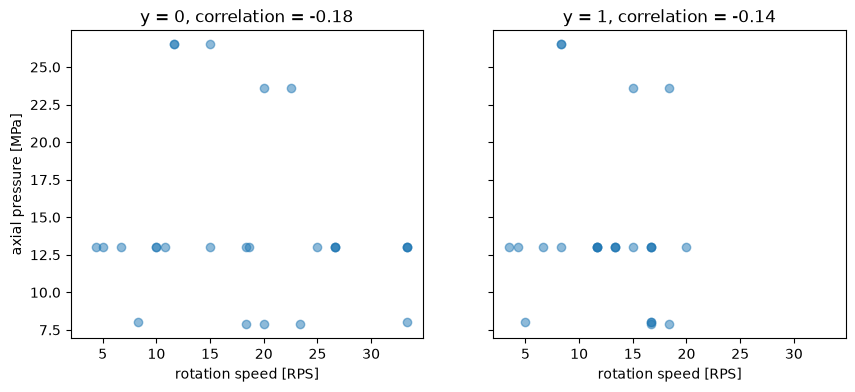

In [3]:
# 2. Training data of each class
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for c, ax in enumerate(axs):
    Xc = X_tr[y_tr == c]
    ax.scatter(Xc[:, 0], Xc[:, 1], alpha=0.5)
    ax.set(title=f'y = {c}, correlation = {np.corrcoef(Xc.T)[0, 1]:.2f}', xlabel='rotation speed [RPS]')
axs[0].set_ylabel('axial pressure [MPa]');

In [4]:
# 3. Test accuracy of the classifier with the highest validation accuracy
best = max(models, key=lambda name: models[name].score(X_va, y_va))
print(f'{best}: test accuracy = {models[best].score(X_te, y_te):.3f}')

Logistic regression: test accuracy = 0.667


In [5]:
# 4. New weld: 15 RPS, 20 MPa
x_new = [[15, 20]]
for name, model in models.items():
    print(f'{name}: p(void) = {model.predict_proba(x_new)[0, 1]:.2f}, label = {model.predict(x_new)[0]}')

Logistic regression: p(void) = 0.45, label = 0
Gaussian NB: p(void) = 0.62, label = 1
